# Monitoria 16/09/2025

# 1. Questão 11 com outros dados

Uma distribuidora de refrigerantes sabe que exposições de final de prateleira são uma maneira efetiva de aumentar vendas de um produto. Porém, existem diversas maneiras de fazer essas exposições: variando o texto exposto, cores usadas e imagens.

![image.jpg](https://upload.wikimedia.org/wikipedia/commons/thumb/2/2d/Endcaps_at_a_Wal-Mart.jpg/800px-Endcaps_at_a_Wal-Mart.jpg)

Um grupo de marketing elaborou três novas exposições de final de prateleira e quer testar sua efetividade. Eles identificaram quinze lojas de tamanho similar e da mesma categoria para fazerem parte do seu estudo. Cada loja irá testar uma das exposições durante um mês. As exposições foram atribuídas de maneira aleatória a cada loja, cada uma das exposições foi testada em 5 lojas diferentes. Os dados observados são o aumento percentual em vendas daquela loja com relação as vendas da loja quando a exposição não está em uso.

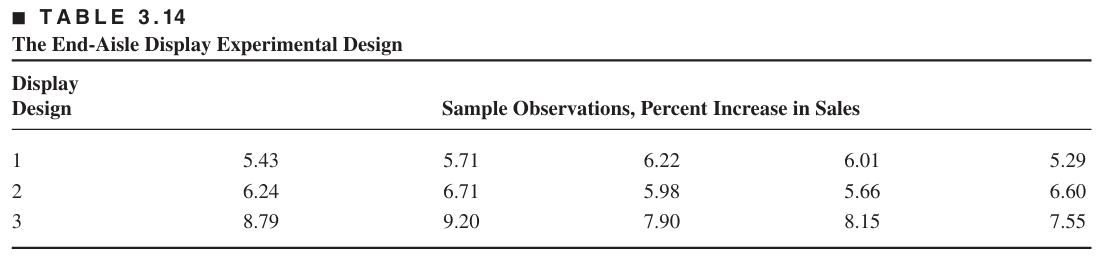

a) Verifique se as condições do teste ANOVA são satisfeitas pelos dados (Normalidade e homocedasticidade). Aplique testes se possível.

In [8]:
# bibliotecas utilizadas
from scipy import stats
import numpy as np
import statsmodels.api as sm
from statsmodels.formula.api import ols
import pandas as pd
# organiza os dados para executar ANOVA
dados = {
"Exposicao": ["1"]*5 +["2"]*5 + ["3"]*5,
"Vendas": [5.43, 5.71, 6.22, 6.01, 5.29,
           6.24, 6.71, 5.98, 5.66, 6.60,
           8.79, 9.20, 7.90, 8.15, 7.55]}
df = pd.DataFrame(dados)
df.head()

,Exposicao,Vendas
0,1,5.43
1,1,5.71
2,1,6.22
3,1,6.01
4,1,5.29


In [7]:
df["Vendas"] = df["Vendas"].astype("float")
exposicoes = df["Exposicao"].unique()
for exposicao in exposicoes:
  df_tipo = df.loc[df["Exposicao"]== exposicao, :]
  print("Exposicao: {}".format(exposicao))
  print("Media:{} ; Variancia: {:.2f}".format(np.mean(df_tipo["Vendas"]),
  np.var(df_tipo["Vendas"])))
  print("Teste de normalidade:")
  print(stats.shapiro(df_tipo["Vendas"]),"\n")
print("Teste para homoscedasticidade:")
print(stats.levene(
df.loc[df['Exposicao'] =="1", "Vendas"],
df.loc[df['Exposicao'] =="2", "Vendas"],
df.loc[df['Exposicao'] =="3", "Vendas"]))

Exposicao: 1
Media:5.731999999999999 ; Variancia: 0.12
Teste de normalidade:
ShapiroResult(statistic=np.float64(0.9539248420512466), pvalue=np.float64(0.7651745070240926)) 

Exposicao: 2
Media:6.2379999999999995 ; Variancia: 0.15
Teste de normalidade:
ShapiroResult(statistic=np.float64(0.9520208702550494), pvalue=np.float64(0.7516156171012727)) 

Exposicao: 3
Media:8.318 ; Variancia: 0.36
Teste de normalidade:
ShapiroResult(statistic=np.float64(0.9589964404169368), pvalue=np.float64(0.8009781135840071)) 

Teste para homoscedasticidade:
LeveneResult(statistic=np.float64(0.7448983715197797), pvalue=np.float64(0.49551298558778356))


b) Conduza uma análise descritiva e uma análise de variâncias em Python (ou em R) para concluir se existem evidências que contribuem para a hipótese de que o ~~tipo de carro influencia na duração do contrato~~ as exposições impactam na venda de maneiras diferentes.

<Axes: xlabel='Exposicao', ylabel='Vendas'>

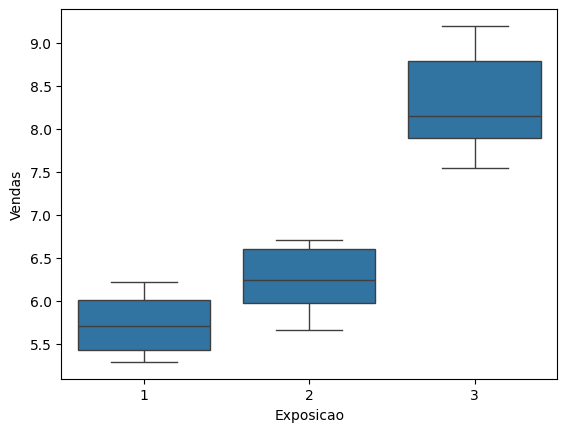

In [2]:
 import seaborn as sns
 # Construcao de um boxplot
 sns.boxplot(df,x = "Exposicao", y = "Vendas")

In [3]:
model = ols('Vendas ~ Exposicao', data=df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

              sum_sq    df          F    PR(>F)
Exposicao  18.783053   2.0  35.772248  0.000009
Residual    3.150440  12.0        NaN       NaN


In [4]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tukey = pairwise_tukeyhsd(endog=df['Vendas'], groups=df['Exposicao'], alpha=0.05)
print(tukey)

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     1      2    0.506 0.2989 -0.3585 1.3705  False
     1      3    2.586    0.0  1.7215 3.4505   True
     2      3     2.08 0.0001  1.2155 2.9445   True
---------------------------------------------------


Montgomery, D.C. Design and Analysis of Experiments, Willey, 9th Edition, 2017.

# 2. Algumas outras questões da lista

# 3. Questão da avaliação